# Pipeline Lengkap Segmentasi Pelanggan UMKM (K-Means Clustering)

Notebook ini berisi alur lengkap *end-to-end* untuk segmentasi pelanggan UMKM:
1. **Muat Dataset & Audit Kualitas Data Awal** (`raw.csv`)
2. **Data Cleaning & Feature Engineering** (Kategori A, B, dan C)
3. **Exploratory Data Analysis (EDA)** (analisis *skewness*, korelasi, dan sebaran demografi)
4. **Pembagian Data (*Train / Validation / Test* 70% / 15% / 15%) & Perbandingan Model pada Data Validation**
5. **Evaluasi Model Final ($k=4$) pada Data Test & Diagnostik Silhouette/PCA**
6. **Grafik Utama Profil Segmen Pelanggan** (*Heatmap Centroid* & Komposisi Segmen)
7. **Analisis Fitur Paling Berpengaruh (*ANOVA F-Score* & $\eta^2$) serta Uji Kewajaran Bisnis**
8. **Penyimpanan Model, Simulasi Prediksi Pelanggan Baru & Form Interaktif Colab**
9. **Ekspor Skrip API FastAPI (`app.py`) & Unduh Model**

## 1. Muat Dataset & Audit Kualitas Data Awal
Membaca `raw.csv` (otomatis memunculkan dialog unggah file jika dijalankan di Google Colab dan file belum tersedia), menyimpan salinan mentah `df_awal`, serta mendata anomali data sebelum pembersihan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Muat data raw.csv
try:
    df = pd.read_csv('raw.csv')
except FileNotFoundError:
    import io
    from google.colab import files
    uploaded = files.upload()
    nama_file = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[nama_file]))

# Simpan salinan data mentah untuk audit sebelum dibersihkan
df_awal = df.copy()

print("Ukuran data mentah:", df_awal.shape)
print("Daftar kolom:", df_awal.columns.tolist())

# 2. Audit jumlah masing-masing masalah kualitas data
duplikat = df_awal.duplicated(subset=['id_pelanggan']).sum()
format_rp = df_awal['total_belanja_rp'].astype(str).str.contains(r'Rp|\.', regex=True, na=False).sum()

kec_raw = df_awal['kecamatan'].dropna().astype(str)
kec_fix = kec_raw.str.strip().str.title().replace({
    'Bdg Wetan': 'Bandung Wetan',
    'Buah Batu': 'Buahbatu'
})
kec_beda = (kec_raw != kec_fix).sum()

outlier_umur = ((df_awal['umur'] < 12) | (df_awal['umur'] > 80)).sum()
kosong_umur = df_awal['umur'].isna().sum()
kosong_rating = df_awal['rating_rata'].isna().sum()

masalah_df = pd.DataFrame({
    'Jenis Masalah': [
        'Data duplikat (id_pelanggan sama)',
        'Format teks pada total_belanja_rp (ada Rp dan titik)',
        'Penulisan kecamatan tidak seragam / disingkat',
        'Outlier pada umur (< 12 atau > 80 tahun)',
        'Data kosong (NaN) pada umur dan rating_rata'
    ],
    'Jumlah Baris': [
        duplikat,
        format_rp,
        kec_beda,
        outlier_umur,
        f"umur: {kosong_umur}, rating_rata: {kosong_rating}"
    ],
    'Cara Penanganan': [
        'Hapus duplikat pakai drop_duplicates() berdasarkan id_pelanggan (pertahankan terbaru)',
        'Hapus tulisan Rp dan titik, lalu ubah tipe datanya ke numerik (float)',
        'Rapikan spasi & huruf kapital, lalu samakan singkatan (Bdg Wetan, Buah Batu)',
        'Ubah nilai outlier jadi NaN dulu, lalu isi dengan nilai median',
        'Isi nilai kosong dengan median masing-masing kolom'
    ],
    'Alasan': [
        'Supaya satu pelanggan tidak dihitung dua kali saat clustering',
        'K-Means hanya dapat menghitung jarak Euclidean dari angka numerik',
        'Agar nama kecamatan yang sama tidak dianggap kategori berbeda saat encoding',
        'Umur tidak valid dapat menggeser rata-rata dan titik pusat klaster',
        'Mempertahankan seluruh rekaman pelanggan tanpa bias dari outlier'
    ]
})

masalah_df

Saving raw.csv to raw.csv
Ukuran data mentah: (10150, 12)
Daftar kolom: ['id_pelanggan', 'tanggal_daftar', 'umur', 'kecamatan', 'channel_utama', 'metode_bayar', 'kategori_favorit', 'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo', 'rating_rata']


,Jenis Masalah,Jumlah Baris,Cara Penanganan,Alasan
0,Data duplikat (id_pelanggan sama),150,Hapus duplikat pakai drop_duplicates() berdasa...,Supaya satu pelanggan tidak dihitung dua kali ...
1,Format teks pada total_belanja_rp (ada Rp dan ...,507,"Hapus tulisan Rp dan titik, lalu ubah tipe dat...",K-Means hanya dapat menghitung jarak Euclidean...
2,Penulisan kecamatan tidak seragam / disingkat,254,"Rapikan spasi & huruf kapital, lalu samakan si...",Agar nama kecamatan yang sama tidak dianggap k...
3,Outlier pada umur (< 12 atau > 80 tahun),100,"Ubah nilai outlier jadi NaN dulu, lalu isi den...",Umur tidak valid dapat menggeser rata-rata dan...
4,Data kosong (NaN) pada umur dan rating_rata,"umur: 208, rating_rata: 812",Isi nilai kosong dengan median masing-masing k...,Mempertahankan seluruh rekaman pelanggan tanpa...


## 2. Data Cleaning & Rekayasa Fitur (*Feature Engineering*)
Membersihkan seluruh anomali pada `df` dan membentuk dua fitur turunan baru:
- **`lama_keanggotaan`**: durasi terdaftar pelanggan (hari) terhadap tanggal referensi `2026-06-30`.
- **`rata_belanja_per_transaksi`**: rasio `total_belanja_rp / jumlah_transaksi_6bln` (*Average Order Value*).

In [2]:
# 1. Hapus duplikat id_pelanggan (pertahankan transaksi terbaru)
df = df.sort_values('hari_sejak_transaksi_terakhir', ascending=True)
df = df.drop_duplicates(subset=['id_pelanggan'], keep='first').copy()

# 2. Bersihkan format 'Rp' dan titik pada total_belanja_rp
df['total_belanja_rp'] = (
    df['total_belanja_rp']
    .astype(str)
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
    .str.strip()
)
df['total_belanja_rp'] = pd.to_numeric(df['total_belanja_rp'])

# 3. Rapikan penulisan nama kecamatan
df['kecamatan'] = df['kecamatan'].str.strip().str.title().replace({
    'Bdg Wetan': 'Bandung Wetan',
    'Buah Batu': 'Buahbatu'
})

# 4. Tangani outlier umur & nilai kosong (umur dan rating_rata)
df.loc[(df['umur'] < 12) | (df['umur'] > 80), 'umur'] = np.nan
df['umur'] = df['umur'].fillna(df['umur'].median())
df['rating_rata'] = df['rating_rata'].fillna(df['rating_rata'].median())

# 5. Rekayasa Fitur Kategori C & Kategori A
tanggal_referensi = pd.Timestamp('2026-06-30')
df['lama_keanggotaan'] = (tanggal_referensi - pd.to_datetime(df['tanggal_daftar'])).dt.days
df['lama_keanggotaan'] = np.maximum(df['lama_keanggotaan'], df['hari_sejak_transaksi_terakhir'])
df['rata_belanja_per_transaksi'] = df['total_belanja_rp'] / df['jumlah_transaksi_6bln']

# 6. Kelompokkan kolom sesuai struktur Kategori A, B, dan C
kategori_A = [
    'jumlah_transaksi_6bln',
    'total_belanja_rp',
    'hari_sejak_transaksi_terakhir',
    'persen_pakai_promo',
    'kategori_favorit'
]

kategori_B = [
    'umur',
    'kecamatan',
    'channel_utama',
    'metode_bayar',
    'rating_rata'
]

kategori_C_olahan = ['lama_keanggotaan']

print(f"Jumlah pelanggan bersih : {len(df):,} baris, {df.shape[1]} kolom")
print(f"Sisa nilai kosong (NaN) : {df[kategori_A + kategori_B + kategori_C_olahan].isnull().sum().sum()}")
print("""
Deskripsi Dataset Hasil Pembersihan (df):
1.  id_pelanggan                  : Kode identitas unik setiap pelanggan
2.  tanggal_daftar                : Tanggal pertama kali pelanggan mendaftar
3.  umur                          : Usia pelanggan dalam tahun (rentang valid 12-80 tahun)
4.  kecamatan                     : Wilayah kecamatan domisili pelanggan (sudah diseragamkan)
5.  jumlah_transaksi_6bln         : Frekuensi transaksi dalam 6 bulan terakhir (Kategori A)
6.  total_belanja_rp              : Total nominal belanja dalam Rupiah (Kategori A)
7.  hari_sejak_transaksi_terakhir : Jarak hari sejak transaksi terakhir / Recency (Kategori A)
8.  persen_pakai_promo            : Persentase transaksi menggunakan promo/diskon (Kategori A)
9.  kategori_favorit              : Kategori produk yang paling sering dibeli (Kategori A)
10. channel_utama                 : Platform/saluran transaksi utama pelanggan (Kategori B)
11. metode_bayar                  : Metode pembayaran yang paling sering digunakan (Kategori B)
12. rating_rata                   : Rata-rata rating kepuasan pelanggan (Kategori B)
13. lama_keanggotaan              : Durasi aktif pelanggan dalam hari (Kategori C - fitur baru)
14. rata_belanja_per_transaksi    : Rata-rata nilai belanja per transaksi (Kategori A - fitur baru)
""")
df[['id_pelanggan', 'lama_keanggotaan', 'rata_belanja_per_transaksi'] + kategori_A].head()

Jumlah pelanggan bersih : 10,000 baris, 14 kolom
Sisa nilai kosong (NaN) : 0

Deskripsi Dataset Hasil Pembersihan (df):
1.  id_pelanggan                  : Kode identitas unik setiap pelanggan
2.  tanggal_daftar                : Tanggal pertama kali pelanggan mendaftar
3.  umur                          : Usia pelanggan dalam tahun (rentang valid 12-80 tahun)
4.  kecamatan                     : Wilayah kecamatan domisili pelanggan (sudah diseragamkan)
5.  jumlah_transaksi_6bln         : Frekuensi transaksi dalam 6 bulan terakhir (Kategori A)
6.  total_belanja_rp              : Total nominal belanja dalam Rupiah (Kategori A)
7.  hari_sejak_transaksi_terakhir : Jarak hari sejak transaksi terakhir / Recency (Kategori A)
8.  persen_pakai_promo            : Persentase transaksi menggunakan promo/diskon (Kategori A)
9.  kategori_favorit              : Kategori produk yang paling sering dibeli (Kategori A)
10. channel_utama                 : Platform/saluran transaksi utama pelanggan (Kategori

,id_pelanggan,lama_keanggotaan,rata_belanja_per_transaksi,jumlah_transaksi_6bln,total_belanja_rp,hari_sejak_transaksi_terakhir,persen_pakai_promo,kategori_favorit
8930,PLG-00557,471,67743.333333,30,2032300,0,21,kopi
5876,PLG-02410,619,30833.333333,12,370000,0,70,roti
5874,PLG-03693,764,75568.000000,25,1889200,0,21,kopi
6907,PLG-05154,281,242200.000000,2,484400,0,14,kue_ulang_tahun
5870,PLG-04561,483,41351.724138,29,1199200,0,16,roti


## 3. Exploratory Data Analysis (EDA)
Memeriksa kemiringan distribusi (*skewness*) pada fitur transaksi sebelum dan sesudah transformasi `np.log1p`, korelasi antar fitur numerik, serta profil demografi pelanggan.

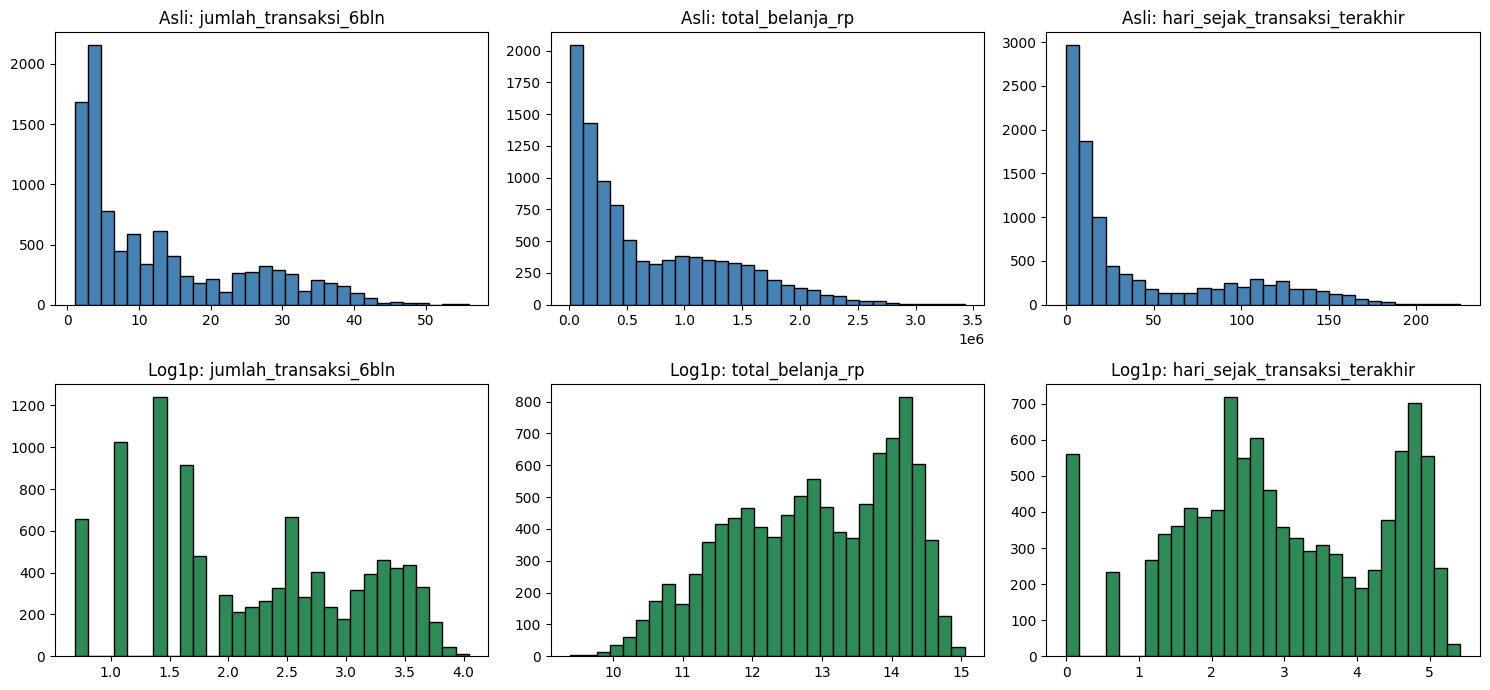

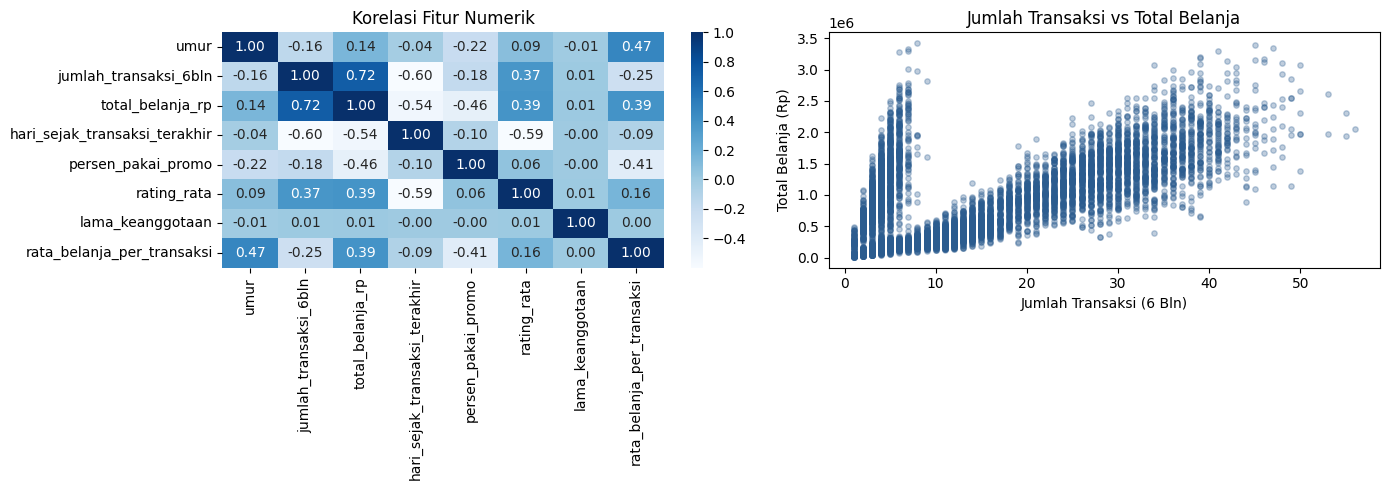

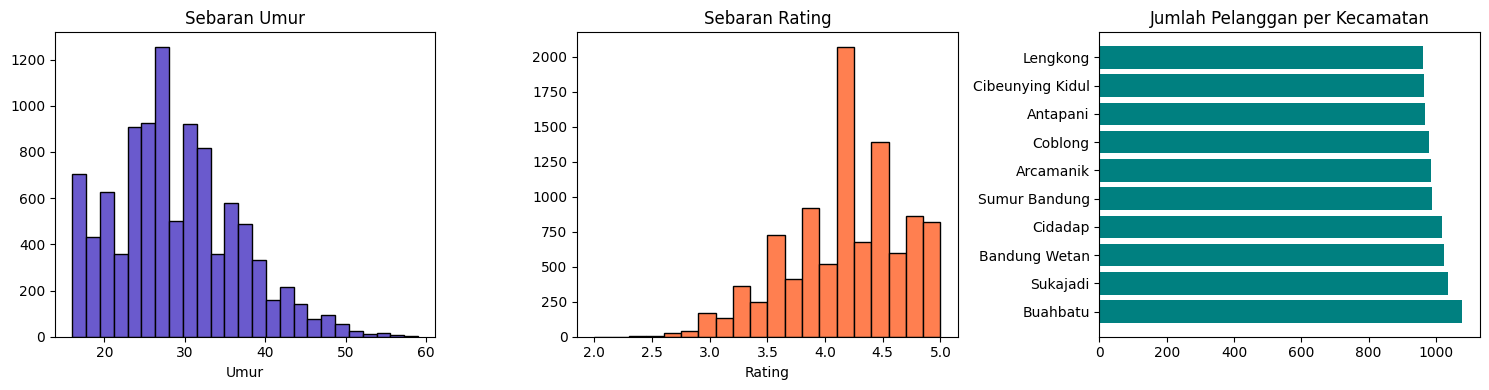

In [3]:
df_plot = df.copy()

# 1. Cek kemiringan (skewness) fitur transaksi sebelum & sesudah log1p
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
fitur_transaksi = ['jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir']

for i, col in enumerate(fitur_transaksi):
    ax[0, i].hist(df_plot[col], bins=30, color='steelblue', edgecolor='black')
    ax[0, i].set_title(f'Asli: {col}')

    ax[1, i].hist(np.log1p(df_plot[col]), bins=30, color='seagreen', edgecolor='black')
    ax[1, i].set_title(f'Log1p: {col}')

plt.tight_layout()
plt.show()

# 2. Cek korelasi antar fitur numerik bersih & hubungan frekuensi vs total belanja
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

kolom_num = df_plot.select_dtypes(include=[np.number]).columns.tolist()
sns.heatmap(df_plot[kolom_num].corr(), annot=True, fmt='.2f', cmap='Blues', ax=ax[0])
ax[0].set_title('Korelasi Fitur Numerik')

ax[1].scatter(df_plot['jumlah_transaksi_6bln'], df_plot['total_belanja_rp'], alpha=0.3, s=15, color='#2b5c8f')
ax[1].set_xlabel('Jumlah Transaksi (6 Bln)')
ax[1].set_ylabel('Total Belanja (Rp)')
ax[1].set_title('Jumlah Transaksi vs Total Belanja')

plt.tight_layout()
plt.show()

# 3. Cek sebaran fitur demografi dan kecamatan
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(df_plot['umur'], bins=25, color='slateblue', edgecolor='black')
ax[0].set_title('Sebaran Umur')
ax[0].set_xlabel('Umur')

ax[1].hist(df_plot['rating_rata'], bins=20, color='coral', edgecolor='black')
ax[1].set_title('Sebaran Rating')
ax[1].set_xlabel('Rating')

kec_counts = df_plot['kecamatan'].value_counts()
ax[2].barh(kec_counts.index, kec_counts.values, color='teal')
ax[2].set_title('Jumlah Pelanggan per Kecamatan')

plt.tight_layout()
plt.show()

## 4. Pembagian Data (*Train / Validation / Test*) & Perbandingan Model pada Data Validation
Agar evaluasi model adil dan bebas dari *data leakage*, 10.000 data bersih dibagi menjadi tiga bagian:
- **Data Train (70% / 7.000 baris)**: digunakan untuk melatih *transformer* (`StandardScaler`, `OneHotEncoder`) dan model klasterisasi.
- **Data Validation (15% / 1.500 baris)**: digunakan untuk membandingkan kinerja **Baseline (11 Fitur)** terhadap kandidat model lainnya (**Perbaikan 1: 5 Fitur Utama Kategori A**, **Perbaikan 2: 4 Pilar Inti Kategori A**, serta **MiniBatchKMeans** pada 4 Pilar Inti) dan menentukan jumlah klaster optimal ($k=4$).
- **Data Test (15% / 1.500 baris)**: disimpan terpisah hingga model final terpilih, lalu digunakan untuk menguji kemampuan generalisasi model final.

Jumlah Data Train      : 7,000 baris (70%)
Jumlah Data Validation : 1,500 baris (15%)
Jumlah Data Test       : 1,500 baris (15%)

=== SILHOUETTE SCORE PADA DATA VALIDATION (k = 2 s.d. 7) ===
 k  Baseline_11_Fitur (Val)  Perbaikan_1_KatA (Val)  Perbaikan_2_Inti_KatA (Val)
 2                   0.2299                  0.3776                       0.4292
 3                   0.2138                  0.4463                       0.5045
 4                   0.2350                  0.4880                       0.6037
 5                   0.1951                  0.4188                       0.5186
 6                   0.1563                  0.3375                       0.4113
 7                   0.1419                  0.2623                       0.3682

=== TABEL PERBANDINGAN BASELINE VS MODEL LAIN PADA DATA VALIDATION (k = 4) ===
                     Model / Skenario Fitur (k=4)  Jumlah Dimensi  Silhouette Train  Silhouette Validation  Calinski-Harabasz (Val)  Davies-Bouldin (Val)
        

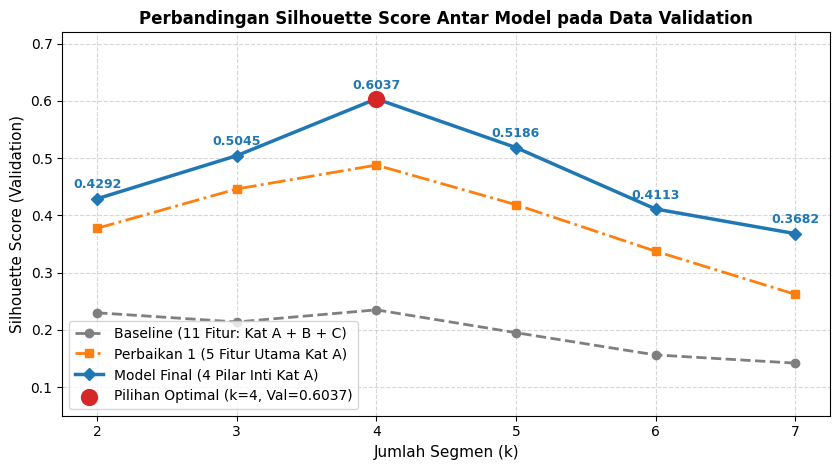

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, silhouette_samples

# 1. Bagi data menjadi Train (70%), Validation (15%), dan Test (15%)
df_train, df_temp = train_test_split(df, test_size=0.30, random_state=42)
df_val, df_test = train_test_split(df_temp, test_size=0.50, random_state=42)

print(f"Jumlah Data Train      : {len(df_train):,} baris (70%)")
print(f"Jumlah Data Validation : {len(df_val):,} baris (15%)")
print(f"Jumlah Data Test       : {len(df_test):,} baris (15%)")

# Helper fungsi untuk menyiapkan 3 representasi fitur (fit HANYA di df_train)
fitur_num_11 = [
    'jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir',
    'persen_pakai_promo', 'umur', 'rating_rata', 'lama_keanggotaan'
]
fitur_kat_11 = ['kategori_favorit', 'kecamatan', 'channel_utama', 'metode_bayar']

fitur_num_5 = ['jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir', 'persen_pakai_promo']
fitur_kat_5 = ['kategori_favorit']

fitur_inti_A = [
    'jumlah_transaksi_6bln',
    'hari_sejak_transaksi_terakhir',
    'persen_pakai_promo',
    'rata_belanja_per_transaksi'
]

def siapkan_log(data_in, kolom_log):
    d = data_in.copy()
    for c in kolom_log:
        d[c] = np.log1p(d[c])
    return d

# Skenario A: Baseline 11 Fitur (25 kolom)
prep_11 = ColumnTransformer([
    ('num', StandardScaler(), fitur_num_11),
    ('kat', OneHotEncoder(drop='first', sparse_output=False), fitur_kat_11)
])
X_tr_11 = prep_11.fit_transform(siapkan_log(df_train[fitur_num_11 + fitur_kat_11], ['jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir']))
X_va_11 = prep_11.transform(siapkan_log(df_val[fitur_num_11 + fitur_kat_11], ['jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir']))

# Skenario B: Perbaikan 1 - 5 Fitur Utama Kategori A (8 kolom)
prep_5 = ColumnTransformer([
    ('num', StandardScaler(), fitur_num_5),
    ('kat', OneHotEncoder(drop='first', sparse_output=False), fitur_kat_5)
])
X_tr_5 = prep_5.fit_transform(siapkan_log(df_train[fitur_num_5 + fitur_kat_5], ['jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir']))
X_va_5 = prep_5.transform(siapkan_log(df_val[fitur_num_5 + fitur_kat_5], ['jumlah_transaksi_6bln', 'total_belanja_rp', 'hari_sejak_transaksi_terakhir']))

# Skenario C: Perbaikan 2 - 4 Pilar Inti Kategori A (4 kolom)
scaler_split = StandardScaler()
X_tr_4 = scaler_split.fit_transform(siapkan_log(df_train[fitur_inti_A], ['jumlah_transaksi_6bln', 'hari_sejak_transaksi_terakhir', 'rata_belanja_per_transaksi']))
X_va_4 = scaler_split.transform(siapkan_log(df_val[fitur_inti_A], ['jumlah_transaksi_6bln', 'hari_sejak_transaksi_terakhir', 'rata_belanja_per_transaksi']))
X_te_4 = scaler_split.transform(siapkan_log(df_test[fitur_inti_A], ['jumlah_transaksi_6bln', 'hari_sejak_transaksi_terakhir', 'rata_belanja_per_transaksi']))

# 2. Perbandingan Silhouette Score pada Data Validation untuk variasi k = 2 s.d. 7
hasil_val_k = []
for k in range(2, 8):
    m11 = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_tr_11)
    m5  = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_tr_5)
    m4  = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_tr_4)

    hasil_val_k.append({
        'k': k,
        'Baseline_11_Fitur (Val)': silhouette_score(X_va_11, m11.predict(X_va_11)),
        'Perbaikan_1_KatA (Val)': silhouette_score(X_va_5, m5.predict(X_va_5)),
        'Perbaikan_2_Inti_KatA (Val)': silhouette_score(X_va_4, m4.predict(X_va_4)),
    })

df_val_k = pd.DataFrame(hasil_val_k)
print("\n=== SILHOUETTE SCORE PADA DATA VALIDATION (k = 2 s.d. 7) ===")
print(df_val_k.round(4).to_string(index=False))

# 3. Tabel Perbandingan Lengkap Baseline vs Model Kandidat Lain pada Data Validation (k = 4)
kandidat_model = [
    ('Baseline: K-Means (11 Fitur / 25 Kolom)', KMeans(n_clusters=4, random_state=42, n_init=10), X_tr_11, X_va_11),
    ('Kandidat 1: K-Means (5 Fitur Utama Kat. A)', KMeans(n_clusters=4, random_state=42, n_init=10), X_tr_5, X_va_5),
    ('Kandidat 2: MiniBatchKMeans (4 Pilar Inti Kat. A)', MiniBatchKMeans(n_clusters=4, random_state=42, n_init=10, batch_size=512), X_tr_4, X_va_4),
    ('Model Final: K-Means (4 Pilar Inti Kat. A)', KMeans(n_clusters=4, random_state=42, n_init=10), X_tr_4, X_va_4),
]

baris_perbandingan = []
model_final_split = None

for nama_m, clf, X_tr_m, X_va_m in kandidat_model:
    clf.fit(X_tr_m)
    lbl_tr = clf.predict(X_tr_m)
    lbl_va = clf.predict(X_va_m)
    baris_perbandingan.append({
        'Model / Skenario Fitur (k=4)': nama_m,
        'Jumlah Dimensi': X_va_m.shape[1],
        'Silhouette Train': silhouette_score(X_tr_m, lbl_tr),
        'Silhouette Validation': silhouette_score(X_va_m, lbl_va),
        'Calinski-Harabasz (Val)': calinski_harabasz_score(X_va_m, lbl_va),
        'Davies-Bouldin (Val)': davies_bouldin_score(X_va_m, lbl_va),
    })
    if 'Model Final' in nama_m:
        model_final_split = clf

df_perbandingan_val = pd.DataFrame(baris_perbandingan)
print("\n=== TABEL PERBANDINGAN BASELINE VS MODEL LAIN PADA DATA VALIDATION (k = 4) ===")
print(df_perbandingan_val.round(4).to_string(index=False))

# Plot kurva perbandingan Validation Silhouette Score
plt.figure(figsize=(8.5, 4.8))
plt.plot(df_val_k['k'], df_val_k['Baseline_11_Fitur (Val)'], marker='o', linestyle='--', color='#7f7f7f', linewidth=2, label='Baseline (11 Fitur: Kat A + B + C)')
plt.plot(df_val_k['k'], df_val_k['Perbaikan_1_KatA (Val)'], marker='s', linestyle='-.', color='#ff7f0e', linewidth=2, label='Perbaikan 1 (5 Fitur Utama Kat A)')
plt.plot(df_val_k['k'], df_val_k['Perbaikan_2_Inti_KatA (Val)'], marker='D', linestyle='-', color='#1f77b4', linewidth=2.5, label='Model Final (4 Pilar Inti Kat A)')

for x, y in zip(df_val_k['k'], df_val_k['Perbaikan_2_Inti_KatA (Val)']):
    plt.text(x, y + 0.018, f"{y:.4f}", ha='center', fontsize=9, fontweight='bold', color='#1f77b4')

skor_val_k4 = df_val_k.loc[df_val_k['k'] == 4, 'Perbaikan_2_Inti_KatA (Val)'].values[0]
plt.scatter([4], [skor_val_k4], color='#d62728', s=130, zorder=5, label=f'Pilihan Optimal (k=4, Val={skor_val_k4:.4f})')
plt.title('Perbandingan Silhouette Score Antar Model pada Data Validation', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Segmen (k)', fontsize=11)
plt.ylabel('Silhouette Score (Validation)', fontsize=11)
plt.xticks(df_val_k['k'])
plt.ylim(0.05, 0.72)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig('grafik_validasi_perbandingan_model.png', dpi=150)
plt.show()

## 5. Evaluasi Hasil Model Final pada Data Test (1.500 Pelanggan)
Setelah **Model Final (K-Means $k=4$ dengan 4 Pilar Inti Kategori A)** terpilih berdasarkan skor tertinggi pada *Data Validation*, model tersebut dievaluasi pada **Data Test** yang benar-benar belum pernah dilihat saat pelatihan maupun pemilihan fitur.

In [5]:
# 1. Evaluasi metrik model final pada Data Train, Validation, dan Test
lbl_tr_fin = model_final_split.predict(X_tr_4)
lbl_va_fin = model_final_split.predict(X_va_4)
lbl_te_fin = model_final_split.predict(X_te_4)

df_evaluasi_test = pd.DataFrame([
    {
        'Dataset': 'Data Train (70%)',
        'Jumlah Sampel': len(X_tr_4),
        'Silhouette Score (↑)': silhouette_score(X_tr_4, lbl_tr_fin),
        'Calinski-Harabasz Index (↑)': calinski_harabasz_score(X_tr_4, lbl_tr_fin),
        'Davies-Bouldin Index (↓)': davies_bouldin_score(X_tr_4, lbl_tr_fin),
    },
    {
        'Dataset': 'Data Validation (15%)',
        'Jumlah Sampel': len(X_va_4),
        'Silhouette Score (↑)': silhouette_score(X_va_4, lbl_va_fin),
        'Calinski-Harabasz Index (↑)': calinski_harabasz_score(X_va_4, lbl_va_fin),
        'Davies-Bouldin Index (↓)': davies_bouldin_score(X_va_4, lbl_va_fin),
    },
    {
        'Dataset': 'Data Test (15% - Final)',
        'Jumlah Sampel': len(X_te_4),
        'Silhouette Score (↑)': silhouette_score(X_te_4, lbl_te_fin),
        'Calinski-Harabasz Index (↑)': calinski_harabasz_score(X_te_4, lbl_te_fin),
        'Davies-Bouldin Index (↓)': davies_bouldin_score(X_te_4, lbl_te_fin),
    }
])

print("=== HASIL EVALUASI MODEL FINAL (k = 4) PADA DATA TEST ===")
print(df_evaluasi_test.round(4).to_string(index=False))

# 2. Latih model produksi pada seluruh 10.000 data bersih untuk pemetaan segmen & deployment
df_A2 = siapkan_log(df[fitur_inti_A], ['jumlah_transaksi_6bln', 'hari_sejak_transaksi_terakhir', 'rata_belanja_per_transaksi'])
scaler_final = StandardScaler()
X_final_scaled = scaler_final.fit_transform(df_A2)

kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
df['segmen'] = kmeans_final.fit_predict(X_final_scaled)

# Pemetaan nama segmen berdasarkan karakteristik median tiap klaster
median_inti = df.groupby('segmen')[fitur_inti_A].median()
mapping_nama = {}
for idx, row in median_inti.iterrows():
    if row['jumlah_transaksi_6bln'] >= 20:
        mapping_nama[idx] = '1. Pelanggan Setia Harian'
    elif row['rata_belanja_per_transaksi'] >= 150000:
        mapping_nama[idx] = '2. Pembeli Borongan & Acara'
    elif row['persen_pakai_promo'] >= 60:
        mapping_nama[idx] = '3. Pemburu Promo Online'
    else:
        mapping_nama[idx] = '4. Pelanggan Mulai Menghilang'

df['nama_segmen'] = df['segmen'].map(mapping_nama)
df['sil_individu'] = silhouette_samples(X_final_scaled, df['segmen'])
rata_sil_akhir = silhouette_score(X_final_scaled, df['segmen'])

# 3. Cek stabilitas proporsi segmen antara Train, Validation, dan Test
mapping_split = {}
med_split = df_train.assign(seg_tmp=lbl_tr_fin).groupby('seg_tmp')[fitur_inti_A].median()
for idx, row in med_split.iterrows():
    if row['jumlah_transaksi_6bln'] >= 20:
        mapping_split[idx] = '1. Pelanggan Setia Harian'
    elif row['rata_belanja_per_transaksi'] >= 150000:
        mapping_split[idx] = '2. Pembeli Borongan & Acara'
    elif row['persen_pakai_promo'] >= 60:
        mapping_split[idx] = '3. Pemburu Promo Online'
    else:
        mapping_split[idx] = '4. Pelanggan Mulai Menghilang'

prop_tr = pd.Series(lbl_tr_fin).map(mapping_split).value_counts(normalize=True) * 100
prop_va = pd.Series(lbl_va_fin).map(mapping_split).value_counts(normalize=True) * 100
prop_te = pd.Series(lbl_te_fin).map(mapping_split).value_counts(normalize=True) * 100

df_proporsi = pd.DataFrame({
    'Train (%)': prop_tr,
    'Validation (%)': prop_va,
    'Test (%)': prop_te
}).sort_index().round(2)

print("\n=== KONSISTENSI PROPORSI SEGMEN DI TRAIN, VALIDATION & TEST (%) ===")
print(df_proporsi.to_string())

=== HASIL EVALUASI MODEL FINAL (k = 4) PADA DATA TEST ===
                Dataset  Jumlah Sampel  Silhouette Score (↑)  Calinski-Harabasz Index (↑)  Davies-Bouldin Index (↓)
       Data Train (70%)           7000                0.6148                   12207.7255                    0.5450
  Data Validation (15%)           1500                0.6037                    2472.3620                    0.5676
Data Test (15% - Final)           1500                0.6075                    2473.3609                    0.5586

=== KONSISTENSI PROPORSI SEGMEN DI TRAIN, VALIDATION & TEST (%) ===
                               Train (%)  Validation (%)  Test (%)
1. Pelanggan Setia Harian          29.93           31.60      30.0
2. Pembeli Borongan & Acara        15.41           14.13      14.0
3. Pemburu Promo Online            24.81           25.20      25.6
4. Pelanggan Mulai Menghilang      29.84           29.07      30.4


## 6. Grafik Utama Hasil Segmentasi (Profil Karakteristik 4 Segmen) & Diagnostik Klaster
Grafik utama di bawah ini merangkum **karakteristik perilaku belanja ke-4 segmen** secara visual (kombinasi *Heatmap Z-Score & Nilai Median Aktual* serta *Komposisi Jumlah Pelanggan*), diikuti visualisasi distribusi koefisien Silhouette dan proyeksi PCA 2D.

=== RINGKASAN PROFIL 4 SEGMEN PELANGGAN UMKM ===
                               jumlah_pelanggan  median_transaksi_6bln  median_rata_belanja_rp  median_hari_terakhir  median_persen_promo  rata_silhouette  persentase_%
nama_segmen                                                                                                                                                             
1. Pelanggan Setia Harian                  3019                   28.0                48110.34                   5.0                 20.0             0.61         30.19
2. Pembeli Borongan & Acara                1501                    4.0               276220.00                  30.0                 12.0             0.63         15.01
3. Pemburu Promo Online                    2499                   11.0                31742.86                  12.0                 82.0             0.62         24.99
4. Pelanggan Mulai Menghilang              2981                    3.0                41433.33            

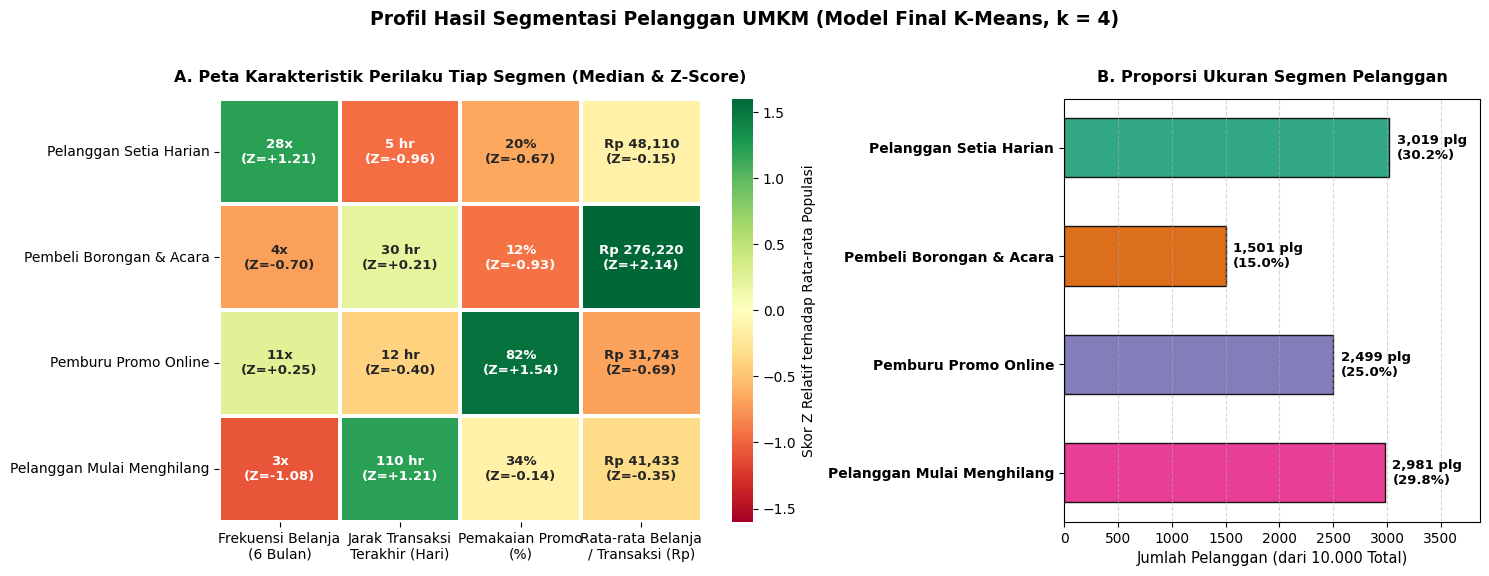

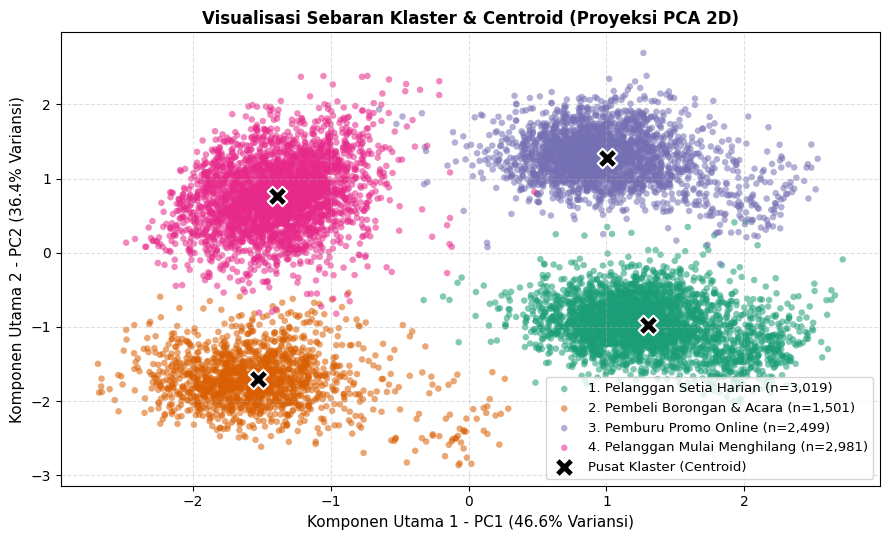

In [6]:
from sklearn.decomposition import PCA

# 1. Ringkasan Profil Perilaku tiap Segmen
urutan_segmen = sorted(df['nama_segmen'].unique())
profil_segmen = df.groupby('nama_segmen').agg(
    jumlah_pelanggan=('id_pelanggan', 'count'),
    median_transaksi_6bln=('jumlah_transaksi_6bln', 'median'),
    median_rata_belanja_rp=('rata_belanja_per_transaksi', 'median'),
    median_hari_terakhir=('hari_sejak_transaksi_terakhir', 'median'),
    median_persen_promo=('persen_pakai_promo', 'median'),
    rata_silhouette=('sil_individu', 'mean')
).reindex(urutan_segmen).round(2)
profil_segmen['persentase_%'] = (profil_segmen['jumlah_pelanggan'] / len(df) * 100).round(2)

print("=== RINGKASAN PROFIL 4 SEGMEN PELANGGAN UMKM ===")
print(profil_segmen.to_string())

# 2. SATU GRAFIK UTAMA YANG PALING MENJELASKAN HASIL: PROFIL SEGMEN PELANGGAN
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1.45, 1]})

# Panel Kiri: Heatmap Z-Score Centroid dengan Anotasi Nilai Median Aktual
df_z = pd.DataFrame(X_final_scaled, columns=fitur_inti_A, index=df.index)
df_z['nama_segmen'] = df['nama_segmen']
z_mean_segmen = df_z.groupby('nama_segmen')[fitur_inti_A].mean().reindex(urutan_segmen)

label_fitur_rapi = [
    'Frekuensi Belanja\n(6 Bulan)',
    'Jarak Transaksi\nTerakhir (Hari)',
    'Pemakaian Promo\n(%)',
    'Rata-rata Belanja\n/ Transaksi (Rp)'
]
label_segmen_rapi = [s.split('. ')[1] for s in urutan_segmen]

# Susun teks anotasi berisi nilai median aktual + skor Z
anotasi_matriks = np.empty(z_mean_segmen.shape, dtype=object)
for r_idx, seg in enumerate(urutan_segmen):
    row_med = profil_segmen.loc[seg]
    vals_aktual = [
        f"{row_med['median_transaksi_6bln']:.0f}x\n(Z={z_mean_segmen.iloc[r_idx, 0]:+.2f})",
        f"{row_med['median_hari_terakhir']:.0f} hr\n(Z={z_mean_segmen.iloc[r_idx, 1]:+.2f})",
        f"{row_med['median_persen_promo']:.0f}%\n(Z={z_mean_segmen.iloc[r_idx, 2]:+.2f})",
        f"Rp {row_med['median_rata_belanja_rp']:,.0f}\n(Z={z_mean_segmen.iloc[r_idx, 3]:+.2f})"
    ]
    for c_idx, txt in enumerate(vals_aktual):
        anotasi_matriks[r_idx, c_idx] = txt

sns.heatmap(
    z_mean_segmen.values,
    annot=anotasi_matriks,
    fmt='',
    cmap='RdYlGn',
    center=0,
    vmin=-1.6,
    vmax=1.6,
    cbar_kws={'label': 'Skor Z Relatif terhadap Rata-rata Populasi'},
    xticklabels=label_fitur_rapi,
    yticklabels=label_segmen_rapi,
    linewidths=1.5,
    linecolor='white',
    ax=axes[0],
    annot_kws={'size': 9.5, 'weight': 'bold'}
)
axes[0].set_title('A. Peta Karakteristik Perilaku Tiap Segmen (Median & Z-Score)', fontsize=11.5, fontweight='bold', pad=12)
axes[0].tick_params(axis='y', rotation=0)

# Panel Kanan: Komposisi Jumlah & Persentase Pelanggan per Segmen
warna_segmen = ['#1b9e77', '#d95f02', '#7570b3', '#e7298a']
y_pos = np.arange(len(urutan_segmen))
jumlah_vals = profil_segmen['jumlah_pelanggan'].values
persen_vals = profil_segmen['persentase_%'].values

bars = axes[1].barh(y_pos, jumlah_vals, color=warna_segmen, height=0.55, edgecolor='black', alpha=0.9)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(label_segmen_rapi, fontsize=10, fontweight='bold')
axes[1].invert_yaxis()
axes[1].set_xlabel('Jumlah Pelanggan (dari 10.000 Total)', fontsize=10.5)
axes[1].set_xlim(0, max(jumlah_vals) * 1.28)
axes[1].grid(True, axis='x', linestyle='--', alpha=0.5)
axes[1].set_title('B. Proporsi Ukuran Segmen Pelanggan', fontsize=11.5, fontweight='bold', pad=12)

for bar, n_val, pct_val in zip(bars, jumlah_vals, persen_vals):
    axes[1].text(
        bar.get_width() + 70,
        bar.get_y() + bar.get_height() / 2,
        f"{n_val:,} plg\n({pct_val:.1f}%)",
        va='center', ha='left', fontsize=9.5, fontweight='bold'
    )

plt.suptitle('Profil Hasil Segmentasi Pelanggan UMKM (Model Final K-Means, k = 4)', fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('grafik_utama_profil_segmen.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Grafik Pendukung: Proyeksi Scatterplot PCA 2D & Centroid
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_final_scaled)
centroids_pca = pca.transform(kmeans_final.cluster_centers_)
variansi = pca.explained_variance_ratio_ * 100

df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]

plt.figure(figsize=(9, 5.5))
for i, nama in enumerate(urutan_segmen):
    subset = df[df['nama_segmen'] == nama]
    plt.scatter(
        subset['PC1'], subset['PC2'],
        c=warna_segmen[i], label=f"{nama} (n={len(subset):,})",
        alpha=0.55, s=22, edgecolors='none'
    )

plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c='black', marker='X', s=200,
    edgecolors='white', linewidth=1.5,
    label='Pusat Klaster (Centroid)', zorder=10
)

plt.title('Visualisasi Sebaran Klaster & Centroid (Proyeksi PCA 2D)', fontsize=12, fontweight='bold')
plt.xlabel(f'Komponen Utama 1 - PC1 ({variansi[0]:.1f}% Variansi)', fontsize=11)
plt.ylabel(f'Komponen Utama 2 - PC2 ({variansi[1]:.1f}% Variansi)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='best', fontsize=9.5)
plt.tight_layout()
plt.savefig('scatterplot_1_pca.png', dpi=150)
plt.show()

## 7. Analisis Fitur Paling Berpengaruh & Uji Kewajaran Bisnis (*Sanity Check*)
Karena K-Means merupakan algoritma *unsupervised*, kontribusi setiap fitur dalam memisahkan segmen diukur menggunakan:
1. **ANOVA F-Score (`f_classif`)**: rasio varians antar-klaster terhadap varians di dalam klaster.
2. **Proporsi Varians Dijelaskan ($\eta^2 = SS_{\text{between}} / SS_{\text{total}}$)**: seberapa besar keragaman fitur tersebut dijelaskan oleh pembagian 4 segmen.

=== PERINGKAT FITUR PALING BERPENGARUH DALAM PEMBENTUKAN SEGMEN ===
 Peringkat                                                         Fitur  ANOVA_F_Score  Eta_Squared_Varians_Dijelaskan_%  p_value
         1             Frekuensi Transaksi 6 Bln (jumlah_transaksi_6bln)     24706.9260                           88.1165      0.0
         2                   Persentase Pakai Promo (persen_pakai_promo)     20801.4665                           86.1934      0.0
         3    Rata-rata Belanja / Transaksi (rata_belanja_per_transaksi)     18212.0898                           84.5340      0.0
         4 Hari Sejak Transaksi Terakhir (hari_sejak_transaksi_terakhir)     10636.0595                           76.1456      0.0


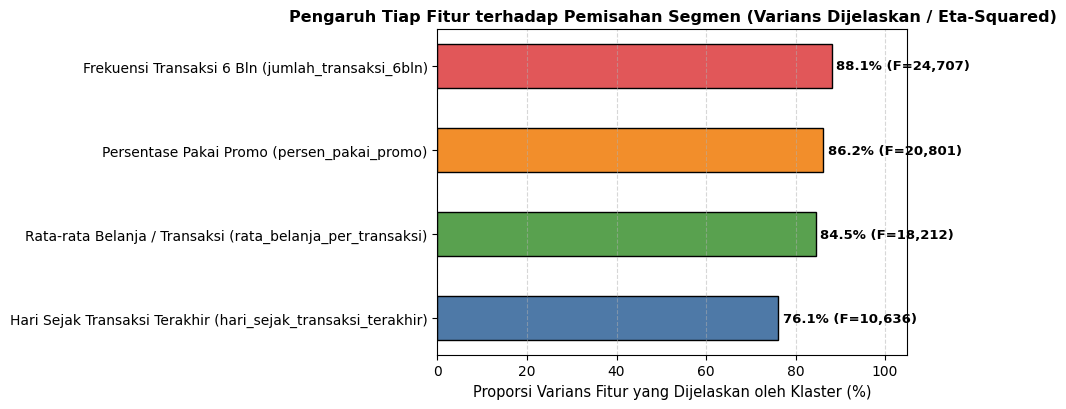


=== INTERPRETASI & UJI KEWAJARAN (APAKAH MASUK AKAL?) ===
1. Sangat masuk akal secara domain bisnis ritel/UMKM karena keempat pilar utama ini
   merepresentasikan dimensi RFM (Recency, Frequency, Monetary) + Sensitivitas Promo:
   - Sensitivitas Promo ('persen_pakai_promo') & Nilai Transaksi ('rata_belanja_per_transaksi')
     menjadi pembeda paling tajam karena secara langsung memisahkan 'Pemburu Promo Online'
     (pemakaian promo tinggi) dan 'Pembeli Borongan & Acara' (nilai per transaksi besar).
   - Frekuensi ('jumlah_transaksi_6bln') memisahkan 'Pelanggan Setia Harian' yang rutin berbelanja
     dari pembeli sesekali.
   - Recency ('hari_sejak_transaksi_terakhir') memisahkan 'Pelanggan Mulai Menghilang' yang sudah
     lama tidak kembali bertransaksi dari pelanggan aktif.
2. Sebaliknya, pada eksperimen Baseline (11 Fitur), variabel demografi statis seperti 'umur',
   'kecamatan', 'metode_bayar', dan 'rating_rata' justru menurunkan Silhouette Score (dari ~0.61
   turun menjadi ~0

In [7]:
from sklearn.feature_selection import f_classif

# 1. Hitung ANOVA F-Score dan Eta-Squared (proporsi varians antar-klaster)
f_vals, p_vals = f_classif(X_final_scaled, df['segmen'])

eta_sq = []
for j in range(X_final_scaled.shape[1]):
    kolom_j = X_final_scaled[:, j]
    grand_mean = np.mean(kolom_j)
    ss_total = np.sum((kolom_j - grand_mean) ** 2)
    ss_between = sum(
        np.sum(df['segmen'] == c) * (np.mean(kolom_j[df['segmen'] == c]) - grand_mean) ** 2
        for c in range(4)
    )
    eta_sq.append(ss_between / ss_total)

nama_fitur_lengkap = {
    'persen_pakai_promo': 'Persentase Pakai Promo (persen_pakai_promo)',
    'rata_belanja_per_transaksi': 'Rata-rata Belanja / Transaksi (rata_belanja_per_transaksi)',
    'jumlah_transaksi_6bln': 'Frekuensi Transaksi 6 Bln (jumlah_transaksi_6bln)',
    'hari_sejak_transaksi_terakhir': 'Hari Sejak Transaksi Terakhir (hari_sejak_transaksi_terakhir)'
}

df_pengaruh = pd.DataFrame({
    'Fitur': [nama_fitur_lengkap[f] for f in fitur_inti_A],
    'ANOVA_F_Score': f_vals,
    'Eta_Squared_Varians_Dijelaskan_%': np.array(eta_sq) * 100,
    'p_value': p_vals
}).sort_values('ANOVA_F_Score', ascending=False).reset_index(drop=True)

df_pengaruh['Peringkat'] = df_pengaruh.index + 1
df_pengaruh = df_pengaruh[['Peringkat', 'Fitur', 'ANOVA_F_Score', 'Eta_Squared_Varians_Dijelaskan_%', 'p_value']]

print("=== PERINGKAT FITUR PALING BERPENGARUH DALAM PEMBENTUKAN SEGMEN ===")
print(df_pengaruh.round(4).to_string(index=False))

# 2. Visualisasi Peringkat Pengaruh Fitur
plt.figure(figsize=(9.5, 4.2))
df_plot_imp = df_pengaruh.sort_values('Eta_Squared_Varians_Dijelaskan_%', ascending=True)
bars = plt.barh(
    df_plot_imp['Fitur'],
    df_plot_imp['Eta_Squared_Varians_Dijelaskan_%'],
    color=['#4e79a7', '#59a14f', '#f28e2b', '#e15759'],
    height=0.52,
    edgecolor='black'
)

for bar, f_sc in zip(bars, df_plot_imp['ANOVA_F_Score']):
    w = bar.get_width()
    plt.text(w + 1.0, bar.get_y() + bar.get_height()/2, f"{w:.1f}% (F={f_sc:,.0f})",
             va='center', ha='left', fontsize=9.5, fontweight='bold')

plt.title('Pengaruh Tiap Fitur terhadap Pemisahan Segmen (Varians Dijelaskan / Eta-Squared)', fontsize=11.5, fontweight='bold')
plt.xlabel('Proporsi Varians Fitur yang Dijelaskan oleh Klaster (%)', fontsize=10.5)
plt.xlim(0, 105)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('grafik_pengaruh_fitur.png', dpi=150)
plt.show()

# 3. Ringkasan Interpretasi & Uji Kewajaran Bisnis
print("""
=== INTERPRETASI & UJI KEWAJARAN (APAKAH MASUK AKAL?) ===
1. Sangat masuk akal secara domain bisnis ritel/UMKM karena keempat pilar utama ini
   merepresentasikan dimensi RFM (Recency, Frequency, Monetary) + Sensitivitas Promo:
   - Sensitivitas Promo ('persen_pakai_promo') & Nilai Transaksi ('rata_belanja_per_transaksi')
     menjadi pembeda paling tajam karena secara langsung memisahkan 'Pemburu Promo Online'
     (pemakaian promo tinggi) dan 'Pembeli Borongan & Acara' (nilai per transaksi besar).
   - Frekuensi ('jumlah_transaksi_6bln') memisahkan 'Pelanggan Setia Harian' yang rutin berbelanja
     dari pembeli sesekali.
   - Recency ('hari_sejak_transaksi_terakhir') memisahkan 'Pelanggan Mulai Menghilang' yang sudah
     lama tidak kembali bertransaksi dari pelanggan aktif.
2. Sebaliknya, pada eksperimen Baseline (11 Fitur), variabel demografi statis seperti 'umur',
   'kecamatan', 'metode_bayar', dan 'rating_rata' justru menurunkan Silhouette Score (dari ~0.61
   turun menjadi ~0.12) karena pelanggan dari kecamatan atau usia yang sama memiliki kebiasaan
   belanja yang beragam, sehingga hanya menambah noise pada perhitungan jarak Euclidean.
""")

## 8. Penyimpanan Paket Model & Simulasi Prediksi Pelanggan Baru
Membungkus `scaler_final`, `kmeans_final`, `mapping_nama`, dan kamus `rekomendasi_promo` ke dalam file `model_segmentasi_umkm.joblib` dan `model_segmentasi_umkm.pkl`, lalu mengujinya pada fungsi prediksi pelanggan baru.

In [8]:
import joblib

# 1. Kamus rekomendasi tindakan spesifik untuk tiap segmen
rekomendasi_promo = {
    '1. Pelanggan Setia Harian': (
        'Program Poin Loyalitas (Stamp Card: Beli 8 Kopi Gratis 1 Roti) - '
        'Hindari potongan harga agar margin keuntungan tetap terjaga.'
    ),
    '2. Pembeli Borongan & Acara': (
        'Paket Bundling Acara & Pengingat Momen Spesial - '
        'Gratis kartu ucapan/lilin ulang tahun atau ekstra minuman untuk pesanan snack box.'
    ),
    '3. Pemburu Promo Online': (
        'Voucher Diskon Bersyarat Minimum Belanja - '
        'Potongan Rp 10.000 dengan min. belanja Rp 50.000 untuk paket bundling kopi + roti.'
    ),
    '4. Pelanggan Mulai Menghilang': (
        'Voucher Win-Back Terbatas - '
        'Diskon 40% untuk kunjungan berikutnya (berlaku 7 hari) disertai survei singkat kepuasan.'
    )
}

# 2. Bungkus dan simpan seluruh komponen model ke file .joblib & .pkl
paket_model = {
    'fitur': fitur_inti_A,
    'scaler': scaler_final,
    'model': kmeans_final,
    'mapping_nama': mapping_nama,
    'rekomendasi_promo': rekomendasi_promo
}

joblib.dump(paket_model, 'model_segmentasi_umkm.joblib')
joblib.dump(paket_model, 'model_segmentasi_umkm.pkl')
print("Model berhasil disimpan sebagai 'model_segmentasi_umkm.joblib' dan 'model_segmentasi_umkm.pkl'.")

# 3. Fungsi prediksi pelanggan baru
model_umkm = joblib.load('model_segmentasi_umkm.joblib')

def prediksi_pelanggan_baru(
    id_pelanggan,
    jumlah_transaksi_6bln,
    total_belanja_rp,
    hari_sejak_transaksi_terakhir,
    persen_pakai_promo,
    kategori_favorit="kopi",
    channel_utama="toko"
):
    rata_belanja = total_belanja_rp / max(jumlah_transaksi_6bln, 1)

    data_baru = pd.DataFrame([{
        'jumlah_transaksi_6bln': jumlah_transaksi_6bln,
        'hari_sejak_transaksi_terakhir': hari_sejak_transaksi_terakhir,
        'persen_pakai_promo': persen_pakai_promo,
        'rata_belanja_per_transaksi': rata_belanja
    }])

    for col in ['jumlah_transaksi_6bln', 'hari_sejak_transaksi_terakhir', 'rata_belanja_per_transaksi']:
        data_baru[col] = np.log1p(data_baru[col])

    data_scaled = model_umkm['scaler'].transform(data_baru)
    klaster_id = model_umkm['model'].predict(data_scaled)[0]
    segmen = model_umkm['mapping_nama'][klaster_id]
    promo = model_umkm['rekomendasi_promo'][segmen]

    info_pengiriman = (
        f"Kirim notifikasi melalui {channel_utama.upper()} dengan menonjolkan "
        f"menu {kategori_favorit.replace('_', ' ')}."
    )

    return segmen, promo, info_pengiriman, rata_belanja

# 4. Uji coba pada 4 contoh profil pelanggan baru
contoh_uji = [
    ("PLG-BARU-01", 26, 1200000, 4, 15, "kopi", "toko"),
    ("PLG-BARU-02", 3, 850000, 25, 10, "kue_ulang_tahun", "toko"),
    ("PLG-BARU-03", 12, 360000, 9, 85, "roti", "gofood"),
    ("PLG-BARU-04", 2, 75000, 120, 35, "kopi", "grabfood"),
]

print("\n=== SIMULASI PREDIKSI PELANGGAN BARU ===\n")
for data in contoh_uji:
    segmen, promo, saluran, aov = prediksi_pelanggan_baru(*data)
    print(f"ID Pelanggan   : {data[0]} (Rata-rata belanja: Rp {aov:,.0f}/transaksi)")
    print(f"Hasil Segmen   : {segmen}")
    print(f"Saran Promo    : {promo}")
    print(f"Strategi Kirim : {saluran}\n")

Model berhasil disimpan sebagai 'model_segmentasi_umkm.joblib' dan 'model_segmentasi_umkm.pkl'.

=== SIMULASI PREDIKSI PELANGGAN BARU ===

ID Pelanggan   : PLG-BARU-01 (Rata-rata belanja: Rp 46,154/transaksi)
Hasil Segmen   : 1. Pelanggan Setia Harian
Saran Promo    : Program Poin Loyalitas (Stamp Card: Beli 8 Kopi Gratis 1 Roti) - Hindari potongan harga agar margin keuntungan tetap terjaga.
Strategi Kirim : Kirim notifikasi melalui TOKO dengan menonjolkan menu kopi.

ID Pelanggan   : PLG-BARU-02 (Rata-rata belanja: Rp 283,333/transaksi)
Hasil Segmen   : 2. Pembeli Borongan & Acara
Saran Promo    : Paket Bundling Acara & Pengingat Momen Spesial - Gratis kartu ucapan/lilin ulang tahun atau ekstra minuman untuk pesanan snack box.
Strategi Kirim : Kirim notifikasi melalui TOKO dengan menonjolkan menu kue ulang tahun.

ID Pelanggan   : PLG-BARU-03 (Rata-rata belanja: Rp 30,000/transaksi)
Hasil Segmen   : 3. Pemburu Promo Online
Saran Promo    : Voucher Diskon Bersyarat Minimum Belanja - Po

In [16]:
#@title Aplikasi Cek Segmen & Rekomendasi Promo Pelanggan UMKM { run: "auto" }
id_pelanggan = "PLG-10001" #@param {type:"string"}
jumlah_transaksi_6bln = 39 #@param {type:"slider", min:1, max:60, step:1}
total_belanja_rp = 1150000 #@param {type:"number"}
hari_sejak_transaksi_terakhir = 85 #@param {type:"slider", min:0, max:250, step:1}
persen_pakai_promo = 25 #@param {type:"slider", min:0, max:100, step:5}
kategori_favorit = "kopi" #@param ["kopi", "roti", "kue_ulang_tahun", "paket_snack"]
channel_utama = "grabfood" #@param ["toko", "gofood", "grabfood", "shopeefood"]

segmen, promo, saluran, aov = prediksi_pelanggan_baru(
    id_pelanggan,
    jumlah_transaksi_6bln,
    total_belanja_rp,
    hari_sejak_transaksi_terakhir,
    persen_pakai_promo,
    kategori_favorit,
    channel_utama
)

print("====================================================")
print(f" HASIL ANALISIS PELANGGAN : {id_pelanggan}")
print("====================================================")
print(f"Rata-rata per Transaksi : Rp {aov:,.0f}")
print(f"Masuk ke Segmen         : {segmen}")
print(f"Rekomendasi Promo       : {promo}")
print(f"Saluran & Produk Target : {saluran}")
print("====================================================")

 HASIL ANALISIS PELANGGAN : PLG-10001
Rata-rata per Transaksi : Rp 29,487
Masuk ke Segmen         : 1. Pelanggan Setia Harian
Rekomendasi Promo       : Program Poin Loyalitas (Stamp Card: Beli 8 Kopi Gratis 1 Roti) - Hindari potongan harga agar margin keuntungan tetap terjaga.
Saluran & Produk Target : Kirim notifikasi melalui GRABFOOD dengan menonjolkan menu kopi.


## 9. Ekspor Skrip Backend FastAPI (`app.py`) & Unduh File Model
Sel di bawah ini otomatis membuat file `app.py` siap pakai untuk integrasi API dan mengunduh file model `.joblib` ke perangkat Anda.

In [10]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel, Field

# Muat paket model dari Colab: scaler, model, mapping_nama, rekomendasi_promo
paket = joblib.load("model_segmentasi_umkm.joblib")

app = FastAPI(title="Segmentasi Pelanggan UMKM")
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_methods=["*"],
    allow_headers=["*"],
)


class Pelanggan(BaseModel):
    jumlah_transaksi_6bln: int = Field(ge=1)
    total_belanja_rp: float = Field(ge=0)
    hari_sejak_transaksi_terakhir: int = Field(ge=0)
    persen_pakai_promo: float = Field(ge=0, le=100)
    kategori_favorit: str = "kopi"
    channel_utama: str = "toko"


@app.get("/")
def cek():
    return {"status": "ok"}


@app.post("/predict")
def predict(p: Pelanggan):
    rata_belanja = p.total_belanja_rp / max(p.jumlah_transaksi_6bln, 1)

    # Urutan kolom harus sama persis dengan saat training
    x = pd.DataFrame([{
        "jumlah_transaksi_6bln": p.jumlah_transaksi_6bln,
        "hari_sejak_transaksi_terakhir": p.hari_sejak_transaksi_terakhir,
        "persen_pakai_promo": p.persen_pakai_promo,
        "rata_belanja_per_transaksi": rata_belanja,
    }])

    # Log transform sama seperti saat training
    for col in ["jumlah_transaksi_6bln", "hari_sejak_transaksi_terakhir", "rata_belanja_per_transaksi"]:
        x[col] = np.log1p(x[col])

    x_scaled = paket["scaler"].transform(x)
    klaster = int(paket["model"].predict(x_scaled)[0])

    segmen = paket["mapping_nama"][klaster]
    promo = paket["rekomendasi_promo"][segmen]
    strategi = (
        f"Kirim notifikasi melalui {p.channel_utama.upper()} dengan menonjolkan "
        f"menu {p.kategori_favorit.replace('_', ' ')}."
    )

    return {
        "klaster": klaster,
        "segmen": segmen,
        "promo": promo,
        "strategi_kirim": strategi,
        "rata_belanja_per_transaksi": round(rata_belanja),
    }

Writing app.py


In [11]:
from google.colab import files

# Unduh file model segmentasi (.joblib) dan skrip API (app.py)
files.download('model_segmentasi_umkm.joblib')
files.download('app.py')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>